<a href="https://colab.research.google.com/github/nattaponm/Teach_Tdating_strom_tracks_HID_CloudProperties/blob/main/notebooks/03_cloud_morphology_kinematics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 3: กายภาพเมฆตามเส้นทาง — ขนาด ความแรง ความเร็ว และการจำแนกกลุ่มพายุ
### Cell morphology and kinematics along T-DaTing tracks: size, centroid, intensity, motion, classification and boxplots

⏱️ เวลาเรียนโดยประมาณ **90 นาที** | ต้องผ่าน: Notebook 1–2

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **คำนวณคุณสมบัติของเซลล์**: พื้นที่, เส้นผ่านศูนย์กลางเทียบเท่า, centroid ถ่วงน้ำหนัก, Zmax/Zmean, พื้นที่แกน ≥ 45 dBZ
2. **คำนวณการเคลื่อนที่** (ความเร็ว ทิศทาง ความยาวเส้นทาง ความคดเคี้ยว) และเทียบกับลมจาก sounding
3. **สรุปเป็นตารางระดับเส้นทาง** และเข้าใจว่าทำไมหน่วยวิเคราะห์ควรเป็น "เส้นทาง" ไม่ใช่ "เซลล์รายเวลา"
4. **จำแนกเส้นทาง** ตามอายุและขนาด แล้วเปรียบเทียบด้วย boxplot และสถิติแบบไม่อิงพารามิเตอร์ (Kruskal–Wallis, Cliff's δ)
5. **ประเมินผลของความละเอียดเวลา (15/10/5 นาที)** ต่อสถิติแต่ละตัว

## 📖 1. แนวคิดและสมการ

### 1.1 คุณสมบัติของเซลล์ (หนึ่งเซลล์ = เส้นทางหนึ่ง ณ เวลาหนึ่ง)
$$ A = N_{px}\times 1\ \mathrm{km^2},\qquad D_{eq} = 2\sqrt{A/\pi} $$
$$ \mathbf{x}_c = \frac{\sum_i \mathbf{x}_i\,Z_i}{\sum_i Z_i}\ \ (Z\ \text{เชิงเส้น} = 10^{\mathrm{dBZ}/10}),\qquad
   Z_{mean} = 10\log_{10}\Big(\frac{1}{N}\sum_i 10^{\mathrm{dBZ}_i/10}\Big) $$
centroid ถ่วงด้วย Z จึง "ดึง" เข้าหาแกนพายุ ไม่ใช่กึ่งกลางทางเรขาคณิต

### 1.2 การเคลื่อนที่ (ทำให้เรียบด้วย moving average 3 จุดก่อนหาอนุพันธ์)
$$ u = \frac{dx_c}{dt},\ \ v = \frac{dy_c}{dt},\qquad |\mathbf{v}| = \sqrt{u^2+v^2},\qquad \theta_{to} = \operatorname{atan2}(u, v) $$
$$ L_{path} = \sum_t |\Delta\mathbf{x}_c|,\qquad L_{straight} = |\mathbf{x}_{c,end}-\mathbf{x}_{c,start}|,\qquad S = L_{path}/L_{straight} $$
⚠️ ที่ Δt = 5 นาที การเลื่อนของ centroid เพียง 1 km ทำให้ความเร็ว "แกว่ง" ±12 km/h → ต้องทำให้เรียบ

### 1.3 หน่วยวิเคราะห์ และสถิติ
- เซลล์ในเส้นทางเดียวกัน **ไม่เป็นอิสระต่อกัน** → สรุปเป็นค่าระดับเส้นทางก่อน (ค่าสูงสุด/มัธยฐาน) แล้วจึงเปรียบเทียบ
- ค่าความเข้ม (Zmax, A45) ใช้ **เฉพาะภาพจริง** (`Zmax_obs`) เพราะภาพสังเคราะห์ทำให้แกนอ่อนลง (NB1)
- **Kruskal–Wallis** (เทียบมัธยฐานหลายกลุ่มโดยใช้อันดับ) $\;H = \frac{12}{N(N+1)}\sum_g n_g\bar{R}_g^2 - 3(N+1)$ + Dunn post-hoc
- **Cliff's δ** (ขนาดผล): $\delta = P(X > Y) - P(X < Y)$; $|\delta|$ < 0.15 เล็กมาก, < 0.33 เล็ก, < 0.47 ปานกลาง, ≥ 0.47 ใหญ่

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–4 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_Tdating_strom_tracks_HID_CloudProperties"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q pysteps==1.21.5 arm_pyart cartopy netCDF4 geopandas metpy cmweather rasterio scikit-image
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "track_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")
DER = os.path.join(DATA, "derived")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import track_tools as tt
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_Tdating_strom_tracks_HID_CloudProperties/data


In [2]:
terr = tt.load_terrain(os.path.join(DER, "KKN_20240503_terrain_1km.nc"))
SETS = {}
for dt in (15, 10, 5):
    S = tt.load_set(DER, tt.MAIN[dt])
    C = tt.add_motion(tt.cell_table(S["labels"], S["Z"], S["times"], S["meta"], terrain=terr), terr, S["meta"])
    T = tt.track_table(C)
    keep = T.index[T.lifetime_min >= 30]
    SETS[dt] = {**S, "C": C[C.track_id.isin(keep)].copy(), "T": tt.classify_tracks(T.loc[keep])}
meta = SETS[15]["meta"]
reports = kt.load_reports(DATA, meta)
date0 = SETS[15]["times"][0].normalize()
for dt, S in SETS.items():
    print(f"Δt = {dt:2d} นาที: {len(S['T'])} เส้นทาง, {len(S['C'])} เซลล์ (ภาพจริง {S['C'].observed.sum()})")

Δt = 15 นาที: 59 เส้นทาง, 229 เซลล์ (ภาพจริง 229)
Δt = 10 นาที: 62 เส้นทาง, 387 เซลล์ (ภาพจริง 121)
Δt =  5 นาที: 68 เส้นทาง, 803 เซลล์ (ภาพจริง 260)


## 🔬 3. ดูทีละเซลล์: พายุนากลาง (Δt = 5 นาที)

บันทึกรูปแล้ว: figures/nb3_naklang_cell_series.png, figures/nb3_naklang_cell_series.pdf


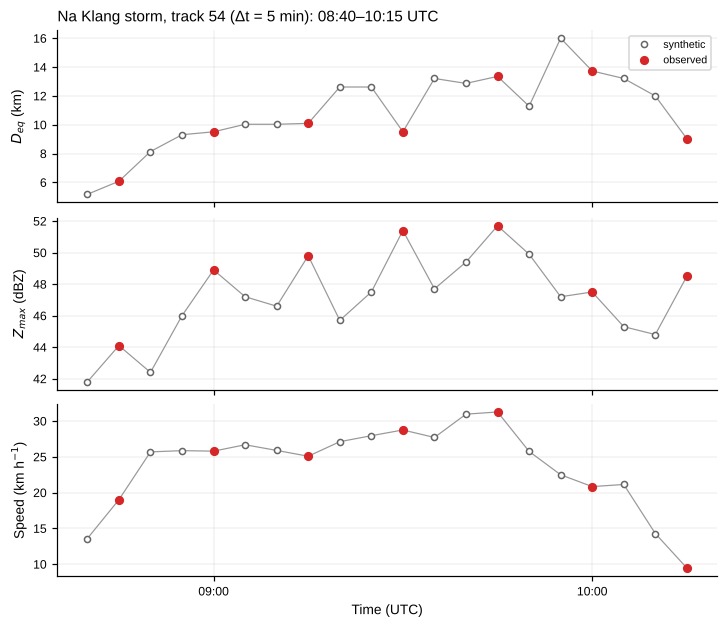

,time,observed,area_km2,deq_km,Zmax,Zmean,A45_km2,speed_kmh,dir_to_deg
429,2024-05-03 08:40:00,False,21.0,5.2,41.8,36.9,0.0,13.6,36.4
430,2024-05-03 08:45:00,True,29.0,6.1,44.1,38.2,0.0,19.0,44.8
431,2024-05-03 08:50:00,False,52.0,8.1,42.4,37.6,0.0,25.7,46.8
432,2024-05-03 08:55:00,False,68.0,9.3,46.0,38.6,2.0,25.9,53.0
433,2024-05-03 09:00:00,True,71.0,9.5,48.9,40.6,6.0,25.8,63.5
434,2024-05-03 09:05:00,False,79.0,10.0,47.2,40.2,4.0,26.7,65.2
435,2024-05-03 09:10:00,False,79.0,10.0,46.6,41.0,7.0,25.9,56.7
436,2024-05-03 09:15:00,True,80.0,10.1,49.8,42.5,16.0,25.1,41.6
437,2024-05-03 09:20:00,False,125.0,12.6,45.7,40.8,1.0,27.1,35.6
438,2024-05-03 09:25:00,False,125.0,12.6,47.5,41.6,14.0,27.9,36.1


In [3]:
s_nk = kt.site(reports, "Na Klang")
S = SETS[5]
near = tt.tracks_near(S["T"], S["C"], s_nk["lon"], s_nk["lat"], t_ref=kt.report_time_utc(s_nk, date0.to_pydatetime()),
                      radius_km=15, window_min=45, meta=meta)
tid = int(near.index[0])
g = S["C"].query("track_id == @tid").copy()
fig, axs = plt.subplots(3, 1, figsize=(6.5, 5.6), sharex=True, layout="constrained")
for ax, col, lab in zip(axs, ("deq_km", "Zmax", "speed_kmh"), ("$D_{eq}$ (km)", "$Z_{max}$ (dBZ)", "Speed (km h$^{-1}$)")):
    ax.plot(g["time"], g[col], "-", color="0.6", lw=0.8)
    ax.plot(g.loc[~g.observed, "time"], g.loc[~g.observed, col], "o", mfc="w", mec="0.4", ms=4, label="synthetic")
    ax.plot(g.loc[g.observed, "time"], g.loc[g.observed, col], "o", color="tab:red", ms=5, label="observed")
    ax.set_ylabel(lab); ax.grid(lw=0.3, alpha=0.5)
axs[0].legend(fontsize=7)
axs[0].set_title(f"Na Klang storm, track {tid} (Δt = 5 min): {g.time.iloc[0]:%H:%M}–{g.time.iloc[-1]:%H:%M} UTC", loc="left")
mp.time_axis(axs[2], interval_h=1, local_top=False)
mp.save_figure(fig, "nb3_naklang_cell_series")
plt.show()
g[["time", "observed", "area_km2", "deq_km", "Zmax", "Zmean", "A45_km2", "speed_kmh", "dir_to_deg"]].round(1).head(12)

สังเกตว่า **Zmax ของภาพสังเคราะห์ (วงกลมขาว) มักต่ำกว่าภาพจริง** และความเร็วแกว่งตามการเลื่อนของ centroid — เป็นเหตุผลที่ใช้ `Zmax_obs` และค่ามัธยฐานของความเร็ว

## 🧭 4. ความเร็วและทิศทางการเคลื่อนที่ เทียบกับลมจาก sounding

บันทึกรูปแล้ว: figures/nb3_speed_direction.png, figures/nb3_speed_direction.pdf


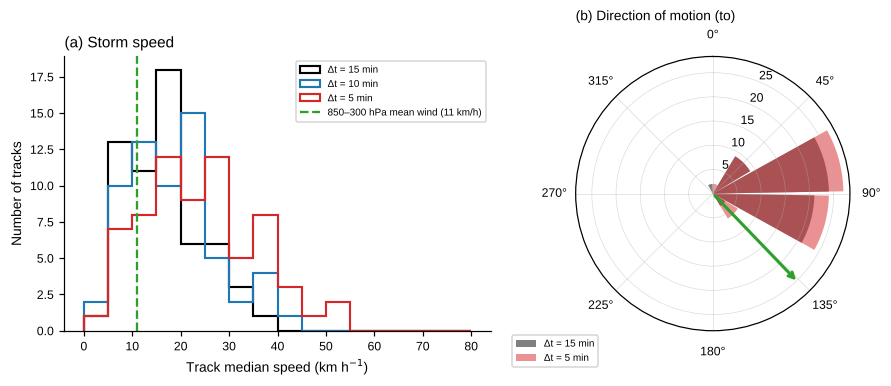

ลมเฉลี่ย 850–300 hPa (00Z): 3.0 m/s ไปทาง 136° | ความเร็วพายุมัธยฐาน: {15: '17 km/h', 10: '18 km/h', 5: '24 km/h'}


In [4]:
from utils import sounding_tools as st
snd = st.load_sounding(os.path.join(DATA, "sounding", "sounding_48431_2024-05-03_00Z.csv"))
us, vs, spd_s, dir_s = st.layer_mean_wind(snd, 850, 300)
fig = plt.figure(figsize=(8.4, 3.4), layout="constrained")
ax0 = fig.add_subplot(1, 2, 1)
cols = {15: "k", 10: "tab:blue", 5: "tab:red"}
bins = np.arange(0, 81, 5)
for dt in (15, 10, 5):
    ax0.hist(SETS[dt]["T"]["speed_kmh"].dropna(), bins=bins, histtype="step", lw=1.4, color=cols[dt], label=f"Δt = {dt} min")
ax0.axvline(spd_s * 3.6, color="tab:green", ls="--", label=f"850–300 hPa mean wind ({spd_s * 3.6:.0f} km/h)")
ax0.set_xlabel("Track median speed (km h$^{-1}$)"); ax0.set_ylabel("Number of tracks"); ax0.legend(fontsize=6.5)
ax0.set_title("(a) Storm speed", loc="left")
ax1 = fig.add_subplot(1, 2, 2, projection="polar")
ax1.set_theta_zero_location("N"); ax1.set_theta_direction(-1)
edges = np.radians(np.arange(0, 361, 30))
for dt in (15, 5):
    h, _ = np.histogram(np.radians(SETS[dt]["T"]["dir_to_deg"].dropna()), bins=edges)
    ax1.bar(edges[:-1] + np.radians(15), h, width=np.radians(28), alpha=0.5, color=cols[dt], label=f"Δt = {dt} min")
ax1.annotate("", xy=(np.radians(dir_s), ax1.get_rmax() * 0.9), xytext=(0, 0),
             arrowprops=dict(arrowstyle="->", color="tab:green", lw=2))
ax1.set_title("(b) Direction of motion (to)", loc="left", fontsize=9)
ax1.legend(fontsize=6.5, loc="lower left", bbox_to_anchor=(-0.25, -0.15))
mp.save_figure(fig, "nb3_speed_direction")
plt.show()
print(f"ลมเฉลี่ย 850–300 hPa (00Z): {spd_s:.1f} m/s ไปทาง {dir_s:.0f}° | ความเร็วพายุมัธยฐาน:",
      {dt: f"{SETS[dt]['T']['speed_kmh'].median():.0f} km/h" for dt in SETS})

- พายุเคลื่อนที่ **เร็วกว่าลมเฉลี่ยจาก sounding เช้าราว 1.5–2 เท่า** และทิศทางส่วนใหญ่ไปทางตะวันออก ขณะที่ลม sounding พัดไปทางตะวันออกเฉียงใต้
- แสดงว่าการเคลื่อนที่ของพายุฤดูร้อนนี้ **ไม่ได้มาจากลมพัดพา (advection) อย่างเดียว** แต่มาจาก **การแพร่ขยาย (propagation)**: เซลล์ใหม่เกิดที่ขอบ cold pool ด้านหน้า
  (สอดคล้องกับ propagation ratio 0.77–0.90 ที่พบใน repo pysteps)
- sounding เป็นเวลา 00Z และอยู่ห่าง ~250 km — ลมตอนบ่ายในพื้นที่จริงอาจต่างไป

## 📋 5. ตารางระดับเส้นทางและการจำแนก

In [5]:
cols_show = ["start", "lifetime_min", "path_km", "sinuosity", "speed_kmh", "deq_max", "Zmax_obs", "A45_max_obs",
             "life_class", "size_class"]
SETS[15]["T"].sort_values("lifetime_min", ascending=False)[cols_show].head(10).round(1)

,start,lifetime_min,path_km,sinuosity,speed_kmh,deq_max,Zmax_obs,A45_max_obs,life_class,size_class
track_id,,,,,,,,,,
45,2024-05-03 09:00:00,120.0,33.6,1.2,9.8,13.5,50.5,21.0,long (≥45 min),medium
38,2024-05-03 08:45:00,90.0,38.4,1.0,20.1,13.7,51.7,36.0,long (≥45 min),medium
4,2024-05-03 06:00:00,90.0,13.2,3.4,2.0,9.8,53.5,25.0,long (≥45 min),small
48,2024-05-03 09:00:00,90.0,39.2,1.1,19.0,14.9,54.0,29.0,long (≥45 min),large
80,2024-05-03 11:45:00,75.0,53.9,1.0,29.9,22.9,48.5,12.0,long (≥45 min),large
3,2024-05-03 06:00:00,60.0,31.1,1.0,22.5,10.6,52.6,11.0,long (≥45 min),medium
20,2024-05-03 07:15:00,60.0,22.2,1.9,7.0,16.5,49.9,14.0,long (≥45 min),large
64,2024-05-03 10:30:00,60.0,19.0,1.0,14.6,13.9,51.0,21.0,long (≥45 min),medium
63,2024-05-03 10:30:00,60.0,34.5,1.0,22.6,23.9,47.0,17.0,long (≥45 min),large


บันทึกรูปแล้ว: figures/nb3_boxplots_lifeclass.png, figures/nb3_boxplots_lifeclass.pdf


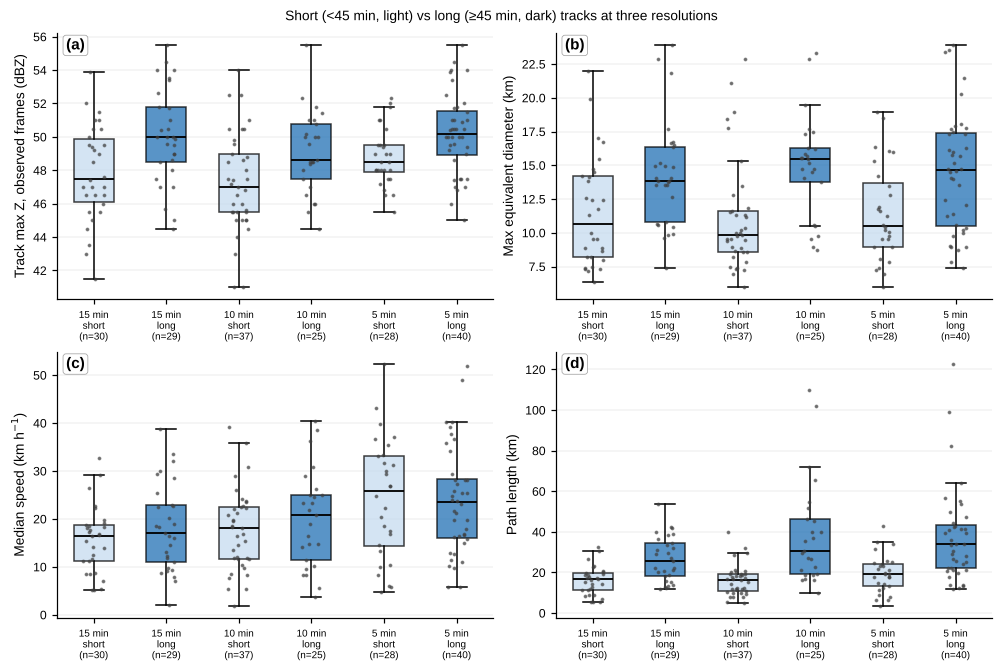

In [6]:
ALL = pd.concat([S["T"].assign(dt=f"{dt} min") for dt, S in SETS.items()])
ALL["dt"] = pd.Categorical(ALL["dt"], ["15 min", "10 min", "5 min"])
ALL["grp"] = pd.Categorical(ALL["dt"].astype(str) + "\n" + ALL["life_class"].astype(str).str.split(" ").str[0],
                            [f"{d} min\n{l}" for d in (15, 10, 5) for l in ("short", "long")])
colors = ["#c6dbef", "#2171b5"] * 3
fig, axs = plt.subplots(2, 2, figsize=(9, 6), layout="constrained")
for ax, (col, lab) in zip(axs.ravel(), (("Zmax_obs", "Track max Z, observed frames (dBZ)"), ("deq_max", "Max equivalent diameter (km)"),
                                        ("speed_kmh", "Median speed (km h$^{-1}$)"), ("path_km", "Path length (km)"))):
    tt.boxplot_groups(ax, ALL, col, "grp", colors=colors, ylabel=lab)
    ax.tick_params(axis="x", labelsize=6.5)
mp.panel_labels(axs.ravel())
fig.suptitle("Short (<45 min, light) vs long (≥45 min, dark) tracks at three resolutions", fontsize=9)
mp.save_figure(fig, "nb3_boxplots_lifeclass")
plt.show()

In [7]:
rows = []
for dt, S in SETS.items():
    T = S["T"]
    for col in ("Zmax_obs", "deq_max", "speed_kmh", "path_km"):
        a = T.loc[T.life_class.astype(str).str.startswith("long"), col]
        b = T.loc[T.life_class.astype(str).str.startswith("short"), col]
        from scipy.stats import mannwhitneyu
        p = mannwhitneyu(a.dropna(), b.dropna())[1] if a.notna().sum() > 2 and b.notna().sum() > 2 else np.nan
        rows.append({"dt_min": dt, "variable": col, "n_long": a.notna().sum(), "n_short": b.notna().sum(),
                     "median_long": a.median(), "median_short": b.median(), "cliffs_delta": tt.cliffs_delta(a, b), "p_MWU": p})
pd.DataFrame(rows).set_index(["variable", "dt_min"]).round(3)

,,n_long,n_short,median_long,median_short,cliffs_delta,p_MWU
variable,dt_min,,,,,,
Zmax_obs,15,29,30,50.000,47.500,0.398,0.009
deq_max,15,29,30,13.866,10.625,0.403,0.008
speed_kmh,15,29,30,17.019,16.527,0.152,0.321
path_km,15,29,30,25.622,16.696,0.568,0.000
Zmax_obs,10,25,37,48.600,47.000,0.376,0.013
deq_max,10,25,37,15.472,9.837,0.551,0.000
speed_kmh,10,25,37,20.809,18.189,0.144,0.344
path_km,10,25,37,30.671,16.144,0.704,0.000
Zmax_obs,5,40,28,50.200,48.500,0.359,0.012


- พายุ **อายุยาว** มีขนาดใหญ่กว่าและ Zmax สูงกว่าพายุอายุสั้น (Cliff's δ บวก) — สอดคล้องกับแนวคิดว่าพายุที่แรงและใหญ่ "เลี้ยงตัวเอง" ได้นานกว่า
- แต่ **ความยาวเส้นทาง** เพิ่มตามอายุเป็นธรรมดา (ยิ่งนานยิ่งไกล) — ไม่ใช่ข้อค้นพบทางฟิสิกส์ ต้องระวัง "ความสัมพันธ์ที่เกิดจากนิยาม"
- ขนาดผลและ p-value **เปลี่ยนตาม Δt** — ข้อสรุปที่ดีควรเห็นได้ในทุกความละเอียด

## 📐 6. จำแนกตามขนาด: พายุใหญ่แรงกว่าหรือไม่?

บันทึกรูปแล้ว: figures/nb3_boxplots_sizeclass.png, figures/nb3_boxplots_sizeclass.pdf


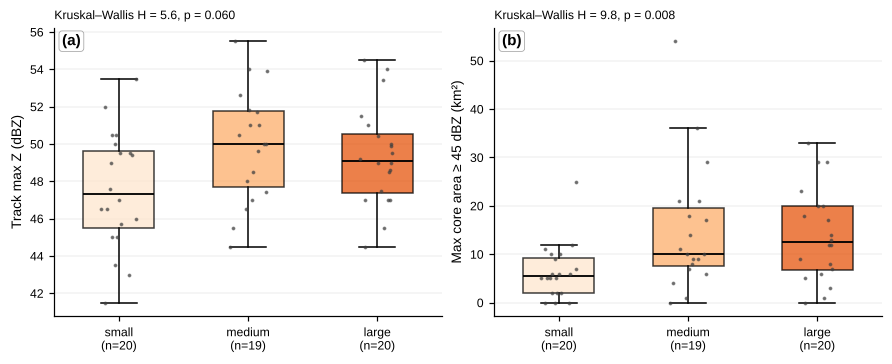

Dunn post-hoc (Bonferroni) สำหรับ Zmax_obs:
              pair      z  p_bonf  cliffs_delta
0  small vs medium -2.321   0.061        -0.429
1   small vs large -1.585   0.339        -0.295
2  medium vs large  0.757   1.000         0.145


In [8]:
T15 = SETS[15]["T"]
fig, axs = plt.subplots(1, 2, figsize=(8, 3.2), layout="constrained")
for ax, col, lab in zip(axs, ("Zmax_obs", "A45_max_obs"), ("Track max Z (dBZ)", "Max core area ≥ 45 dBZ (km²)")):
    tt.boxplot_groups(ax, T15, col, "size_class", colors=["#fee6ce", "#fdae6b", "#e6550d"], ylabel=lab)
    H, p, dunn = tt.kruskal_dunn(T15, col, "size_class")
    ax.set_title(f"Kruskal–Wallis H = {H:.1f}, p = {p:.3f}", loc="left", fontsize=8)
mp.panel_labels(axs)
mp.save_figure(fig, "nb3_boxplots_sizeclass")
plt.show()
print("Dunn post-hoc (Bonferroni) สำหรับ Zmax_obs:")
print(tt.kruskal_dunn(T15, "Zmax_obs", "size_class")[2].round(3))

---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 3.1: ความเร็วจากเส้นทาง vs ความเร็วจาก optical flow
คำนวณ motion field ด้วย pysteps (Lucas–Kanade) จากภาพจริงคู่ 09:15–09:30 และ 09:30–09:45 UTC
หาความเร็วมัธยฐานใน pixel ที่ Z ≥ 35 dBZ แล้วเทียบกับความเร็วมัธยฐานของเส้นทางที่ Δt = 15 นาทีในช่วง 09:00–10:00 UTC

**คำถาม:** สองวิธีวัด "การเคลื่อนที่" คนละอย่างอย่างไร? (คำใบ้: optical flow ติดตามรูปแบบทั้งภาพ, T-DaTing ติดตามแกนของเซลล์)

<details>
<summary><b>💡 คำใบ้</b></summary>

- `from pysteps import motion; V = motion.get_method("LK")(np.nan_to_num(Z15[i-1:i+2], nan=-15), verbose=False)`
- `spd, d = kt.speed_dir(V, Z15[i] >= 35, km_per_px=1.0, dt_min=15)`
- เส้นทางในช่วงเวลา: `T15[(T15.start <= t1) & (T15.end >= t0)]`

</details>

In [9]:
# ✍️ แบบฝึกหัด 3.1 — เขียนโค้ดของคุณที่นี่

In [10]:
#@title ✅ เฉลยแบบฝึกหัด 3.1
from pysteps import motion
import contextlib, io
Z15, t15 = SETS[15]["Z"], list(SETS[15]["times"])
res = []
for hhmm in ("09:30", "09:45"):
    i = t15.index(date0.to_pydatetime().replace(hour=int(hhmm[:2]), minute=int(hhmm[3:])))
    with contextlib.redirect_stdout(io.StringIO()):
        V = motion.get_method("LK")(np.nan_to_num(Z15[i - 2:i + 1], nan=-15.0), verbose=False)
    spd, d = kt.speed_dir(V, np.nan_to_num(Z15[i], nan=-15) >= 35, km_per_px=1.0, dt_min=15)
    res.append({"time": hhmm, "optical_flow_kmh": spd, "optical_flow_dir": d})
t0_, t1_ = date0 + pd.Timedelta(hours=9), date0 + pd.Timedelta(hours=10)
sel = T15[(T15.start <= t1_) & (T15.end >= t0_)]
print(pd.DataFrame(res).round(1))
print(f"\nเส้นทาง T-DaTing ที่มีอยู่ช่วง 09–10 UTC: {len(sel)} เส้น | ความเร็วมัธยฐาน {sel.speed_kmh.median():.0f} km/h, ทิศมัธยฐาน {sel.dir_to_deg.median():.0f}°")
of = pd.DataFrame(res)["optical_flow_kmh"].mean()
print("→ optical flow วัดการเลื่อนของ 'รูปแบบ' ฝนทั้งพื้นที่ (ถ่วงด้วยพื้นที่ echo ขนาดใหญ่), T-DaTing วัดการเลื่อนของ centroid แกนพายุแต่ละเซลล์")
if of > sel.speed_kmh.median():
    print(f"  ที่นี่ optical flow ({of:.0f} km/h) เร็วกว่า T-DaTing ({sel.speed_kmh.median():.0f} km/h): ระบบฝนขนาดใหญ่ขยายตัว/แพร่ไปข้างหน้า"
          "\n  ขณะที่แกนของเซลล์แต่ละก้อนเคลื่อนช้ากว่า และเส้นทางที่เกือบอยู่กับที่ดึงค่ามัธยฐานลง")
else:
    print("  ที่นี่ T-DaTing เร็วกว่า: centroid กระโดดเมื่อเซลล์ใหม่เกิดด้านหน้า (propagation)")

Pysteps configuration file found at: /usr/local/lib/python3.13/dist-packages/pysteps/pystepsrc



    time  optical_flow_kmh  optical_flow_dir
0  09:30              27.7              79.8
1  09:45              30.0              80.8

เส้นทาง T-DaTing ที่มีอยู่ช่วง 09–10 UTC: 17 เส้น | ความเร็วมัธยฐาน 17 km/h, ทิศมัธยฐาน 99°
→ optical flow วัดการเลื่อนของ 'รูปแบบ' ฝนทั้งพื้นที่ (ถ่วงด้วยพื้นที่ echo ขนาดใหญ่), T-DaTing วัดการเลื่อนของ centroid แกนพายุแต่ละเซลล์
  ที่นี่ optical flow (29 km/h) เร็วกว่า T-DaTing (17 km/h): ระบบฝนขนาดใหญ่ขยายตัว/แพร่ไปข้างหน้า
  ขณะที่แกนของเซลล์แต่ละก้อนเคลื่อนช้ากว่า และเส้นทางที่เกือบอยู่กับที่ดึงค่ามัธยฐานลง


### 🧪 แบบฝึกหัด 3.2: พายุอายุยาว "แรงกว่า" จริงหรือ เมื่อคำนึงถึงขนาด?
พายุใหญ่มักอายุยาว และมักมี Zmax สูงเพราะมี pixel มากกว่า (โอกาสเจอค่าสูงมากขึ้น) — ทดสอบความสัมพันธ์ **อายุ–Zmax_obs** ที่ Δt = 15 นาที
(1) Spearman ρ ปกติ (2) partial Spearman โดยควบคุม `deq_max` ด้วย `tt.partial_spearman`

**คำถาม:** หลังควบคุมขนาดแล้ว ความสัมพันธ์ยังเหลืออยู่หรือไม่? แปลผลอย่างไร

<details>
<summary><b>💡 คำใบ้</b></summary>

- `spearmanr(T15.lifetime_min, T15.Zmax_obs, nan_policy="omit")`
- `tt.partial_spearman(T15, "lifetime_min", "Zmax_obs", "deq_max")` คืน (ρ, p, n)

</details>

In [11]:
# ✍️ แบบฝึกหัด 3.2 — เขียนโค้ดของคุณที่นี่

In [12]:
#@title ✅ เฉลยแบบฝึกหัด 3.2
from scipy.stats import spearmanr
rows = []
for dt, S in SETS.items():
    T = S["T"]
    r0, p0 = spearmanr(T.lifetime_min, T.Zmax_obs, nan_policy="omit")
    r1, p1, n = tt.partial_spearman(T, "lifetime_min", "Zmax_obs", "deq_max")
    rows.append({"dt_min": dt, "n": n, "rho": r0, "p": p0, "partial_rho|size": r1, "partial_p": p1})
print(pd.DataFrame(rows).set_index("dt_min").round(3))
pr = pd.DataFrame(rows).set_index("dt_min")
kept = [dt for dt in pr.index if pr.loc[dt, "partial_p"] < 0.05]
print(f"\n→ หลังควบคุมขนาด partial ρ ยังมีนัยสำคัญที่ Δt = {kept} นาที" if kept else "\n→ หลังควบคุมขนาดไม่มี Δt ใดมีนัยสำคัญ")
print("  ส่วนที่ลดลง = ความสัมพันธ์ที่ 'ผ่าน' ขนาดของพายุ (พายุใหญ่ → ทั้งแรงและอายุยาว)"
      "\n  ส่วนที่เหลือ = อายุสัมพันธ์กับความแรงแม้ขนาดเท่ากัน (เช่น updraft แรงอยู่ได้นาน) — แต่ผลไม่เสถียรข้าม Δt จึงต้องระวัง")

         n    rho      p  partial_rho|size  partial_p
dt_min                                               
15      59  0.410  0.001             0.378      0.003
10      62  0.253  0.047             0.139      0.280
5       68  0.346  0.004             0.278      0.022

→ หลังควบคุมขนาด partial ρ ยังมีนัยสำคัญที่ Δt = [15, 5] นาที
  ส่วนที่ลดลง = ความสัมพันธ์ที่ 'ผ่าน' ขนาดของพายุ (พายุใหญ่ → ทั้งแรงและอายุยาว)
  ส่วนที่เหลือ = อายุสัมพันธ์กับความแรงแม้ขนาดเท่ากัน (เช่น updraft แรงอยู่ได้นาน) — แต่ผลไม่เสถียรข้าม Δt จึงต้องระวัง


### 🧪 แบบฝึกหัด 3.3: สถิติใดไวต่อความละเอียดเวลามากที่สุด?
สำหรับตัวแปรระดับเส้นทาง `lifetime_min, path_km, sinuosity, speed_kmh, deq_max, Zmax_obs, Zmax_all, A45_max_obs`
คำนวณ **อัตราส่วนมัธยฐาน 5 นาที / 15 นาที** และเรียงลำดับจากต่างมากไปน้อย

**คำถาม:** ทำไม `Zmax_all` กับ `Zmax_obs` จึงต่างกันในการตอบสนองต่อ Δt? ตัวแปรใดควรรายงานพร้อมคำเตือนเรื่อง Δt

<details>
<summary><b>💡 คำใบ้</b></summary>

- `SETS[5]["T"][cols].median() / SETS[15]["T"][cols].median()`
- เรียงตาม `abs(np.log(ratio))`

</details>

In [13]:
# ✍️ แบบฝึกหัด 3.3 — เขียนโค้ดของคุณที่นี่

In [14]:
#@title ✅ เฉลยแบบฝึกหัด 3.3
cols = ["lifetime_min", "path_km", "sinuosity", "speed_kmh", "deq_max", "Zmax_obs", "Zmax_all", "A45_max_obs"]
med = pd.DataFrame({f"{dt} min": SETS[dt]["T"][cols].median() for dt in (15, 10, 5)})
med["ratio_5/15"] = med["5 min"] / med["15 min"]
med = med.iloc[np.argsort(-np.abs(np.log(med["ratio_5/15"].astype(float))))]
print(med.round(2))
print(f"\n→ ไวที่สุด: {', '.join(med.index[:3])} — อายุและความยาวเพิ่มเพราะภาพสังเคราะห์เชื่อมเส้นทาง, ความเร็วเพิ่มเพราะ centroid ที่ถี่ขึ้น 'แกว่ง' มากขึ้น"
      "\n  (ความยาวเส้นทางที่วัดถี่ขึ้นยาวขึ้น — ปัญหาเดียวกับการวัดความยาวชายฝั่ง)")
print("  Zmax_all ≈ Zmax_obs เพราะค่าสูงสุดของเส้นทางมักอยู่ในภาพจริง (ภาพสังเคราะห์ linZ อ่อนกว่า) — ค่าสูงสุดจึงทนต่อ Δt แต่ค่าเฉลี่ยตามเวลาไม่ทน"
      "\n  ในงานวิจัยต้องรายงาน Δt ทุกครั้ง และเลือกตัวแปรที่ไม่ขึ้นกับการสุ่มตัวอย่างเวลาเมื่อเปรียบเทียบข้ามการศึกษา")

              15 min  10 min  5 min  ratio_5/15
lifetime_min   30.00   40.00  45.00        1.50
speed_kmh      16.61   18.34  23.79        1.43
path_km        18.95   18.78  24.44        1.29
sinuosity       1.02    1.04   1.16        1.13
A45_max_obs     9.00    6.50  10.00        1.11
deq_max        13.54   11.31  12.61        0.93
Zmax_obs       49.20   48.00  49.50        1.01
Zmax_all       49.20   48.35  49.50        1.01

→ ไวที่สุด: lifetime_min, speed_kmh, path_km — อายุและความยาวเพิ่มเพราะภาพสังเคราะห์เชื่อมเส้นทาง, ความเร็วเพิ่มเพราะ centroid ที่ถี่ขึ้น 'แกว่ง' มากขึ้น
  (ความยาวเส้นทางที่วัดถี่ขึ้นยาวขึ้น — ปัญหาเดียวกับการวัดความยาวชายฝั่ง)
  Zmax_all ≈ Zmax_obs เพราะค่าสูงสุดของเส้นทางมักอยู่ในภาพจริง (ภาพสังเคราะห์ linZ อ่อนกว่า) — ค่าสูงสุดจึงทนต่อ Δt แต่ค่าเฉลี่ยตามเวลาไม่ทน
  ในงานวิจัยต้องรายงาน Δt ทุกครั้ง และเลือกตัวแปรที่ไม่ขึ้นกับการสุ่มตัวอย่างเวลาเมื่อเปรียบเทียบข้ามการศึกษา


---
## 📝 สรุป
- คุณสมบัติเซลล์ (A, D_eq, centroid, Zmax, A45) และการเคลื่อนที่ คำนวณได้จาก label ของ T-DaTing โดยตรง
- พายุ 3 พ.ค. เคลื่อนที่ **เร็วกว่าลม sounding** และไปทางตะวันออก — บ่งชี้การแพร่ขยายจาก cold pool มากกว่าการพัดพา
- พายุอายุยาวมักใหญ่และแรงกว่า แต่ต้องแยกผลของ **ขนาด** และ **ความสัมพันธ์จากนิยาม** (อายุ ↔ ความยาวเส้นทาง)
- ความยาวเส้นทาง ความคดเคี้ยว และความแรงจากทุกภาพ **ไวต่อ Δt** — ใช้ค่าจากภาพจริงเมื่อเปรียบเทียบความเข้ม

### ❓ คำถามชวนคิด
1. ถ้าจะจำแนกพายุเป็น "เซลล์เดี่ยว / กลุ่มเซลล์ / แนวพายุ" จากข้อมูลนี้ จะใช้ตัวแปรใดบ้าง?
2. ทำไมพายุบางเส้นทางจึงเคลื่อนสวนทิศกับลมระดับกลาง? (คำใบ้: Corfidi vectors, propagation)
3. ถ้าจะทำนายว่าเส้นทางใหม่ที่เพิ่งเกิดจะอยู่นานเกิน 45 นาทีหรือไม่ ควรใช้คุณสมบัติใดในช่วง 15–30 นาทีแรก?

**🚀 ต่อยอด (ป.โท):** สร้างโมเดล logistic regression ทำนาย `life_class` จากคุณสมบัติช่วงแรกของเส้นทาง (D_eq, Zmax, dA/dt) และประเมินด้วย cross-validation — เป็นพื้นฐานของ **nowcasting อายุพายุ**

### 📚 เอกสารอ้างอิง
- Dixon, M., & Wiener, G. (1993). TITAN. *J. Atmos. Oceanic Technol.*, 10, 785–797.
- Corfidi, S. F. (2003). Cold pools and MCS propagation: Forecasting the motion of downwind-developing MCSs. *Wea. Forecasting*, 18, 997–1017.
- Goudenhoofdt, E., & Delobbe, L. (2013). Statistical characteristics of convective storms in Belgium derived from volumetric weather radar observations. *J. Appl. Meteor. Climatol.*, 52, 918–934.
- Cliff, N. (1993). Dominance statistics: Ordinal analyses to answer ordinal questions. *Psychological Bulletin*, 114, 494–509.
- Wilks, D. S. (2019). *Statistical Methods in the Atmospheric Sciences* (4th ed.). Elsevier.